In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from scipy.stats import linregress
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid

In [2]:
#load npz file
mixture_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Mixture.npy.gz', "r")
mixture_all_cycles.append(np.float32(np.load(fn)))

for i in range(1, 4):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_threshold_flip_booldhsarr_basis_mixture_to0thresh-0.5_to1thresh0.5_cycle'+str(i)+'_CT20220314.npz'
    cycle_np_file = np.load(filename)
    mixture_all_cycles.append(cycle_np_file['new_decomp_mixture'])

mixture_all_cycles = np.array(mixture_all_cycles)

1
2
3


In [3]:
#load npz file
basis_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Basis.npy.gz', "r")
basis_all_cycles.append(np.float32(np.load(fn)))

for i in range(1, 4):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_threshold_flip_booldhsarr_basis_mixture_to0thresh-0.5_to1thresh0.5_cycle'+str(i)+'_CT20220314.npz'
    cycle_np_file = np.load(filename)
    basis_all_cycles.append(cycle_np_file['new_decomp_basis'])

basis_all_cycles = np.array(basis_all_cycles)

1
2
3


In [4]:
n_components, n_DHSs = mixture_all_cycles[0].shape

In [5]:
mixture_all_cycles.shape

(4, 16, 3591898)

In [6]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)

#top 10%
DHS_metadata['ind'] = DHS_metadata.index
DHS_metadata_sortby_mean_signal = DHS_metadata.sort_values(['mean_signal'], ascending=False)
top_10_percent_DHSs = DHS_metadata_sortby_mean_signal.iloc[:int(np.round(n_DHSs/10))]
top_10_percent_DHSs_inds = np.array(top_10_percent_DHSs['ind'])
top_10_percent_DHSs_identifiers = np.array(top_10_percent_DHSs['identifier'])

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [7]:
#loading biosample metadata
tsv_file = open("/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_metadata.tsv")
biosample_df = pd.read_csv(tsv_file, delimiter="\t")

In [8]:
#load npz file
added_delta_all_cycles = []
removed_delta_all_cycles = []
added_flat_inds_all_cycles = []
removed_flat_inds_all_cycles = []

for i in range(1, 4):
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_threshold_flip_added_removed_delta_flatinds_to0thresh-0.5_to1thresh0.5_cycle'+str(i)+'_CT20220315.npz'
    cycle_np_file = np.load(filename)
    added_delta_all_cycles.append(cycle_np_file['added_delta'])
    removed_delta_all_cycles.append(cycle_np_file['removed_delta'])
    added_flat_inds_all_cycles.append(cycle_np_file['added_flat_inds'])
    removed_flat_inds_all_cycles.append(cycle_np_file['removed_flat_inds'])

In [9]:
filtered_added_delta_all_cycles = []
filtered_added_flat_inds_all_cycles = []

for i in range(3):
    print(i)
    #when i=0, that is referring to cycle 1 in biosample, DHS, and delta arrays, and we want to compare to 
    #the previous cycle (original) array value
    if i==0:
        #read in 733 sample x 3.5+ million DHS presence/absence matrix
        dhs_arr = np.load('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy')
        
    #when i=1, that is referring to cycle 2 in biosample, DHS, and delta arrays, and we want to compare to 
    #the previous cycle (cycle 1) array value
    else:
        filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_threshold_flip_booldhsarr_basis_mixture_to0thresh-0.5_to1thresh0.5_cycle'+str(i)+'_CT20220314.npz'
        np_file = np.load(filename)
        dhs_arr = np_file['new_dhs_array']
    
    n_biosamples, n_DHSs = dhs_arr.shape
    
    added_flat_inds_single_cycle = []
    delta_vals_single_cycle = []
    
    #when i=1, that is referring to cycle 2 in biosample, DHS, and delta arrays, and we want to compare to 
    #the previous cycle (cycle 1) array value
    for flat_ind, delta in zip(added_flat_inds_all_cycles[i], added_delta_all_cycles[i]):
        biosample = flat_ind // n_DHSs
        dhs = flat_ind % n_DHSs
        if ~dhs_arr[biosample, dhs]:
            added_flat_inds_single_cycle.append(flat_ind)
            delta_vals_single_cycle.append(delta)
    
    del dhs_arr
    filtered_added_flat_inds_all_cycles.append(np.array(added_flat_inds_single_cycle))
    filtered_added_delta_all_cycles.append(np.array(delta_vals_single_cycle))

0
1
2


**Removed Biosamples**

In [18]:
all_0_biosample_inds = np.where(np.sum(basis_all_cycles, axis=2)==0)

all_0_biosample_inds_cycle1 = all_0_biosample_inds[1][all_0_biosample_inds[0]==1]
all_0_biosample_inds_cycle2 = all_0_biosample_inds[1][all_0_biosample_inds[0]==2]
all_0_biosample_inds_cycle3 = all_0_biosample_inds[1][all_0_biosample_inds[0]==3]

In [25]:
#finding removed biosample_inds
removed_biosample_inds_all_cycles = []
for i in range(3):
    removed_biosample_inds_all_cycles.append(removed_flat_inds_all_cycles[i]  // n_DHSs)
    
#finding removed biosample_inds
filtered_added_biosample_inds_all_cycles = []
for i in range(3):
    filtered_added_biosample_inds_all_cycles.append(filtered_added_flat_inds_all_cycles[i]  // n_DHSs)

In [43]:
#finding the change in call numbers for all biosamples
biosamples = np.arange(733)
all_biosample_net_count = []
for b in biosamples:
    biosample_net_count = []
    biosample_net_count.append(biosample_df.loc[b]['DHSs in Index'])
    for i in range(3):
        removed = len(removed_biosample_inds_all_cycles[i][removed_biosample_inds_all_cycles[i]==b])
        added = len(filtered_added_biosample_inds_all_cycles[i][filtered_added_biosample_inds_all_cycles[i]==b])
        biosample_net_count.append(biosample_net_count[i]+added-removed)
    all_biosample_net_count.append(biosample_net_count)
all_biosample_net_count = np.array(all_biosample_net_count)

In [72]:
biosample_df.loc[all_0_biosample_inds_cycle3]

,library order,Biosample name,Vocabulary representative,DCC Experiment ID,DCC Library ID,DCC Biosample ID,Altius Aggregation ID,Altius Library ID,Altius Biosample ID,Replicate indicators,...,Library cleanup,DNaseI units/mL,Amount Nucleic Acid (ng),Nuclei count,Protease inhibitor,Library sequencing date,Reads used,DCC SPOT score,Per-biosample peaks,DHSs in Index
9,10,GM12878,NaN,ENCSR000EMT,ENCLB441ZZZ,ENCBS857VGC,AG4214,LN1614,DS9432,DS10671,...,new Sucrose,200.0,15,NaN,NaN,2008-07-25,29049982,0.5464,30405,30327
218,219,fHeart,NaN,ENCSR536NGW,ENCLB740GHK,ENCBS312JJA,AG9112,LN3462,DS15839,NaN,...,minElute,80.0,22,4800000.0,A+Sucrose,2010-07-20,24834995,0.4732,17901,17466
230,231,fHeart,NaN,ENCSR533VAF,ENCLB909WAN,ENCBS708NLN,AG9099,LN3702,DS16500,NaN,...,minElute,120.0,100,7600000.0,A+Sucrose,2010-09-01,33607731,0.4864,30939,30482
391,392,Mesendoderm,NaN,ENCSR714DIF,ENCLB383SUW,ENCBS084NIJ,AG8942,LN4376,DS18732,DS19310,...,minElute,80.0,37.3,6090000.0,Buffer A,2011-04-08,22910870,0.5299,29948,29792
568,569,Caki2,NaN,ENCSR515EWI,ENCLB538RFP,ENCBS461KDA,AG7535,LN20837A,DS24205A,DS24211A,...,Sucrose,100.0,50,8800000.0,PBS+A,2013-07-09,14019118,0.5607,31692,31588


In [74]:
np.mean(np.array(biosample_df['DCC SPOT score']))

0.5001987721691677

Text(0.5, 1.0, 'Net Change in Positive DHS Calls for Removed Biosamples\nDelta Threshold Flip, Threshold=-0.5/0.5')

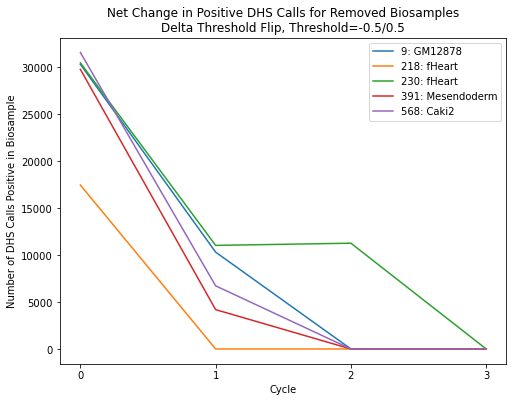

In [79]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

all_0_biosamples = np.array(biosample_df.loc[all_0_biosample_inds_cycle3].index)
all_0_biosample_str = np.char.add(all_0_biosamples.astype(str), np.array([': ']*5))
all_0_biosample_str = np.char.add(all_0_biosample_str, np.array(biosample_df.loc[all_0_biosamples]['Biosample name']))

for i in range(5):
    plt.plot(np.arange(4), all_biosample_net_count[all_0_biosamples[i], :])

plt.legend(all_0_biosample_str)
plt.xticks([0, 1, 2, 3])
# plt.yscale('symlog')
# plt.xlim([0, 175])
# plt.xlim([22453, 22553])
plt.xlabel('Cycle')
plt.ylabel('Number of DHS Calls Positive in Biosample')
plt.title('Net Change in Positive DHS Calls for Removed Biosamples\nDelta Threshold Flip, Threshold=-0.5/0.5')

**How does mean DHS signal change after DHSs are removed each cycle** 

In [114]:
not_0_dhs_inds = np.where(np.sum(mixture_all_cycles, axis=1)!=0)

not_0_dhs_inds_cycle1 = not_0_dhs_inds[1][not_0_dhs_inds[0]==1]
not_0_dhs_inds_cycle2 = not_0_dhs_inds[1][not_0_dhs_inds[0]==2]
not_0_dhs_inds_cycle3 = not_0_dhs_inds[1][not_0_dhs_inds[0]==3]

In [156]:
print(len(not_0_dhs_inds_cycle1))
print(len(not_0_dhs_inds_cycle2))
print(len(not_0_dhs_inds_cycle3))

763678
590660
578701


In [145]:
print(np.mean(DHS_metadata['mean_signal']))
print(np.mean(DHS_metadata.loc[not_0_dhs_inds_cycle1]['mean_signal']))
print(np.mean(DHS_metadata.loc[not_0_dhs_inds_cycle2]['mean_signal']))
print(np.mean(DHS_metadata.loc[not_0_dhs_inds_cycle3]['mean_signal']))

0.6401371981706325
1.264281370497913
1.4055064172012248
1.4156450239057674


**Top 10% DHSs for each Mixture**

In [10]:
#quantitatively comparing mixture embeddings
mixture_all_cycles_10per = mixture_all_cycles[:, :, top_10_percent_DHSs_inds]

**Top comp of basis and top 10% mixtures**

In [11]:
#top comps
mixture_all_cycles_10per_top_comp = np.argmax(mixture_all_cycles_10per, axis=1)
mixture_all_cycles_10per_top_comp_val = np.max(mixture_all_cycles_10per, axis=1)

#sum
mixture_all_cycles_10per_sum = np.sum(mixture_all_cycles_10per, axis=1)

In [12]:
mixture_all_cycles_10per_top_comp_notall0 = np.where(mixture_all_cycles_10per_sum==0, 
                                                     np.nan, 
                                                     mixture_all_cycles_10per_top_comp)

mixture_all_cycles_10per_top_comp_val_notall0 = np.where(mixture_all_cycles_10per_sum==0, 
                                                         np.nan, 
                                                         mixture_all_cycles_10per_top_comp_val)

mixture_all_cycles_10per[np.where(mixture_all_cycles_10per_sum==0)[0],
                         :, 
                         np.where(mixture_all_cycles_10per_sum==0)[1]]=np.nan

In [13]:
#top comps
basis_all_cycles_top_comp = np.argmax(basis_all_cycles, axis=2)
basis_all_cycles_top_comp_val = np.max(basis_all_cycles, axis=2)

#sum
basis_all_cycles_sum = np.sum(basis_all_cycles, axis=2)

In [14]:
basis_all_cycles_top_comp_notall0 = np.where(basis_all_cycles_sum==0, 
                                             np.nan, 
                                             basis_all_cycles_top_comp)

basis_all_cycles_top_comp_val_notall0 = np.where(basis_all_cycles_sum==0, 
                                                 np.nan, 
                                                 basis_all_cycles_top_comp_val)

basis_all_cycles[np.where(basis_all_cycles_sum==0)[0],
                 np.where(basis_all_cycles_sum==0)[1],
                 :]=np.nan

**Mixture (top 10%) and Basis Purity**

In [15]:
#top 10% DHSs
mixture_all_cycles_10per_top_comp_val = np.nanmax(mixture_all_cycles_10per, axis=1)
mixture_all_cycles_10per_nansum = np.nansum(mixture_all_cycles_10per, axis=1)

mixture_all_cycles_10per_pur_by_sum = mixture_all_cycles_10per_top_comp_val / mixture_all_cycles_10per_nansum

/tmp/ipykernel_119939/2851208689.py:2: RuntimeWarning: All-NaN slice encountered
  mixture_all_cycles_10per_top_comp_val = np.nanmax(mixture_all_cycles_10per, axis=1)


In [16]:
basis_all_cycles_top_comp_val = np.nanmax(basis_all_cycles, axis=2)
basis_all_cycles_nansum = np.nansum(basis_all_cycles, axis=2)

basis_all_cycles_pur_by_sum = basis_all_cycles_top_comp_val / basis_all_cycles_nansum

/tmp/ipykernel_119939/603180168.py:1: RuntimeWarning: All-NaN slice encountered
  basis_all_cycles_top_comp_val = np.nanmax(basis_all_cycles, axis=2)


Text(0.5, 1.07, 'NMF Loading Purity (by Top Component Value/Sum of Components)\nDelta Threshold Flip, Threshold=-0.5/0.5')

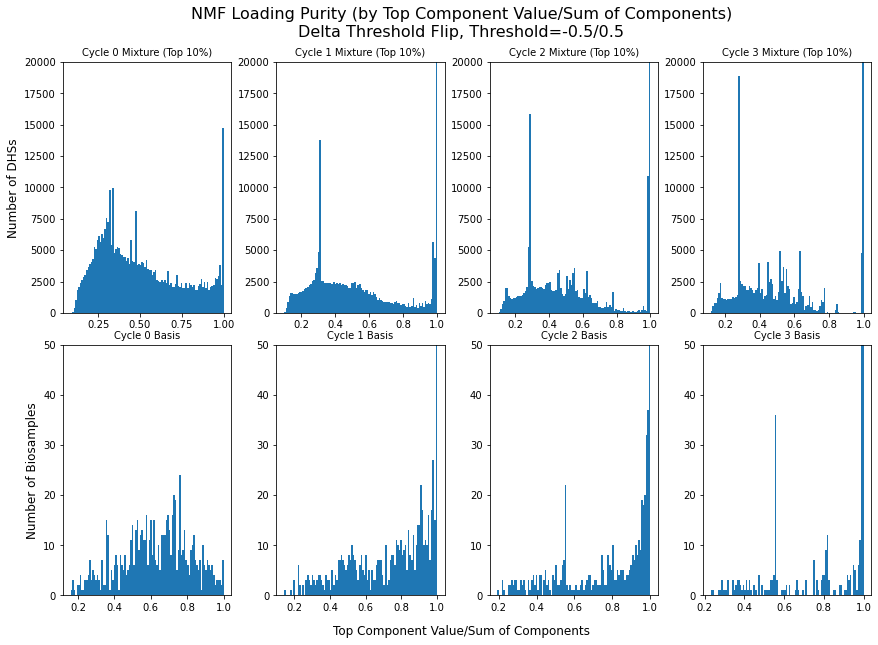

In [17]:
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(12,8))
fig.patch.set_facecolor('white')
fig.tight_layout()

axes = axes.ravel()
for ind in range(4):
    axes[ind].hist(mixture_all_cycles_10per_pur_by_sum[ind], bins=100)
    axes[ind+4].hist(basis_all_cycles_pur_by_sum[ind], bins=100)
    axes[ind].set_ylim([0, 20000])#70000
    axes[ind+4].set_ylim([0, 50])#500
    axes[ind].set_title('Cycle '+str(ind)+' Mixture (Top 10%)', fontsize=10)
    axes[ind+4].set_title('Cycle %s Basis' %(ind), fontsize=10)

axes[0].set_ylabel('Number of DHSs', fontsize=12)
axes[4].set_ylabel('Number of Biosamples', fontsize=12)
fig.text(0.5, -0.02, 'Top Component Value/Sum of Components', ha='center', fontsize=12)
plt.suptitle('NMF Loading Purity (by Top Component Value/Sum of Components)\nDelta Threshold Flip, Threshold=-0.5/0.5', fontsize=16, x=0.5, y=1.07)

In [18]:
#finding the number of comps it takes to make up 50% of loading sum
threshold = 0.5
basis_purity_count_all_cycles = []
for cycle in range(4):
    count_per_cycle = []
    for biosample in range(len(basis_all_cycles[0, :, 0])):
        loading_sum = basis_all_cycles_nansum[cycle, biosample]
        loading = basis_all_cycles[cycle, biosample, :]
        loading_sorted = -np.sort(-loading)
        count = 0
        running_sum = 0
        while running_sum < (threshold * loading_sum):
            running_sum += loading_sorted[count]
            count += 1
        count_per_cycle.append(count)
    basis_purity_count_all_cycles.append(count_per_cycle)
basis_purity_count_all_cycles = np.array(basis_purity_count_all_cycles)

In [19]:
#finding the number of comps it takes to make up 50% of loading sum
threshold = 0.5
mixture_purity_count_all_cycles_10per = []
for cycle in range(4):
    count_per_cycle = []
    for dhs in range(len(mixture_all_cycles_10per[0, 0, :])):
        loading_sum = mixture_all_cycles_10per_nansum[cycle, dhs]
        loading = mixture_all_cycles_10per[cycle, :, dhs]
        loading_sorted = -np.sort(-loading)
        count = 0
        running_sum = 0
        while running_sum < (threshold * loading_sum):
            running_sum += loading_sorted[count]
            count += 1
        count_per_cycle.append(count)
    mixture_purity_count_all_cycles_10per.append(count_per_cycle)
mixture_purity_count_all_cycles_10per = np.array(mixture_purity_count_all_cycles_10per)

In [20]:
for i in basis_purity_count_all_cycles:
    print(np.min(i))

1
0
0
0


Text(0.5, 1.07, 'NMF Loading Purity (by Number of Components Making Up 50% of Loading Sum)\nDelta Threshold Flip, Threshold=-0.5/0.5')

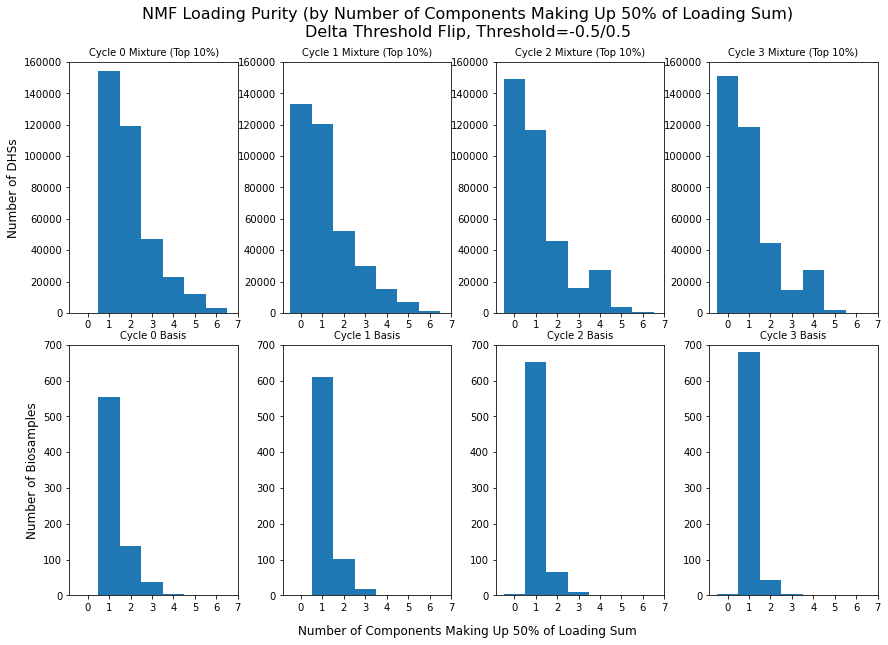

In [21]:
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(12,8))
fig.patch.set_facecolor('white')
fig.tight_layout()

axes = axes.ravel()
for ind in range(4):
    axes[ind].hist(mixture_purity_count_all_cycles_10per[ind], width=1, align='left', bins=[0, 1, 2, 3, 4, 5, 6, 7])
    axes[ind+4].hist(basis_purity_count_all_cycles[ind], width=1, align='left', bins=[0, 1, 2, 3, 4, 5, 6, 7])
    axes[ind].set_ylim([0, 160000])#70000
    axes[ind+4].set_ylim([0, 700])#500
    axes[ind].set_title('Cycle '+str(ind)+' Mixture (Top 10%)', fontsize=10)
    axes[ind+4].set_title('Cycle %s Basis' %(ind), fontsize=10)
    axes[ind].set_xticks([0, 1, 2, 3, 4, 5, 6, 7])
    axes[ind+4].set_xticks([0, 1, 2, 3, 4, 5, 6, 7])
#     axes[ind].set_xlim([0, 7])
#     axes[ind+4].set_xlim([0, 7])

axes[0].set_ylabel('Number of DHSs', fontsize=12)
axes[4].set_ylabel('Number of Biosamples', fontsize=12)
fig.text(0.5, -0.02, 'Number of Components Making Up 50% of Loading Sum', ha='center', fontsize=12)
plt.suptitle('NMF Loading Purity (by Number of Components Making Up 50% of Loading Sum)\nDelta Threshold Flip, Threshold=-0.5/0.5', fontsize=16, x=0.5, y=1.07)

**Heatmaps (of just DHSs that change component)**

In [42]:
heatmap_mixture_all_cycles_10per_top_comp_comparison = np.zeros((3, 16,16), dtype=int)

changed_dhss_all_cycles = []
changed_dhss_original_comp = []
changed_dhss_new_comp = []
changed_dhss_original_comp_val = []
changed_dhss_new_comp_val = []

for i in range(3):
    changed_dhss_1_cycle = []
    original_comp = []
    new_comp = []
    original_comp_val = []
    new_comp_val = []
    
    for comp1, comp0, dhs, val1, val0 in zip(mixture_all_cycles_10per_top_comp_notall0[i+1], 
                                             mixture_all_cycles_10per_top_comp_notall0[i], 
                                             range(len(mixture_all_cycles_10per_top_comp_notall0[0])),
                                             mixture_all_cycles_10per_top_comp_val_notall0[i+1], 
                                             mixture_all_cycles_10per_top_comp_val_notall0[i],):
        if ((comp1!=comp0) and (~np.isnan(comp0)) and (~np.isnan(comp1))):
            comp0 = comp0.astype(int)
            comp1 = comp1.astype(int)
            heatmap_mixture_all_cycles_10per_top_comp_comparison[i, comp1, comp0] += 1
            changed_dhss_1_cycle.append(dhs)
            original_comp.append(comp0)
            new_comp.append(comp1)
            original_comp_val.append(val0)
            new_comp_val.append(val1)
            
    changed_dhss_all_cycles.append(np.array(changed_dhss_1_cycle))
    changed_dhss_original_comp.append(np.array(original_comp))
    changed_dhss_new_comp.append(np.array(new_comp))
    changed_dhss_original_comp_val.append(np.array(original_comp_val))
    changed_dhss_new_comp_val.append(np.array(new_comp_val))

changed_all_dhss_all_cycles = []
for i in changed_dhss_all_cycles:
    changed_all_dhss_all_cycles.append(top_10_percent_DHSs_inds[i])

In [43]:
changed_all_dhss_all_cycles_arr = []
for i in changed_all_dhss_all_cycles:
    changed_all_dhss_all_cycles_arr.extend(i)
changed_all_dhss_all_cycles_arr = np.array(changed_all_dhss_all_cycles_arr)
    
changed_dhss_original_comp_arr = []
for i in changed_dhss_original_comp:
    changed_dhss_original_comp_arr.extend(i)
changed_dhss_original_comp_arr = np.array(changed_dhss_original_comp_arr)
    
changed_dhss_new_comp_arr = []
for i in changed_dhss_new_comp:
    changed_dhss_new_comp_arr.extend(i)
changed_dhss_new_comp_arr = np.array(changed_dhss_new_comp_arr)
    
changed_dhss_original_comp_val_arr = []
for i in changed_dhss_original_comp_val:
    changed_dhss_original_comp_val_arr.extend(i)
changed_dhss_original_comp_val_arr = np.array(changed_dhss_original_comp_val_arr)
    
changed_dhss_new_comp_val_arr = []
for i in changed_dhss_new_comp_val:
    changed_dhss_new_comp_val_arr.extend(i)
changed_dhss_new_comp_val_arr = np.array(changed_dhss_new_comp_val_arr)

In [44]:
heatmap_mixture_all_cycles_10per_top_comp_comparison_sum = np.sum(heatmap_mixture_all_cycles_10per_top_comp_comparison, axis=0)

In [45]:
np.sum(heatmap_mixture_all_cycles_10per_top_comp_comparison_sum)

56334

Text(0.5, 1.0, 'Comparing Changed DHS Top Components of Previous and New NMF Mixtures Summed Across All Cycles\nDelta Threshold Flip, Threshold=-0.5/0.5, Top 10% of DHSs')

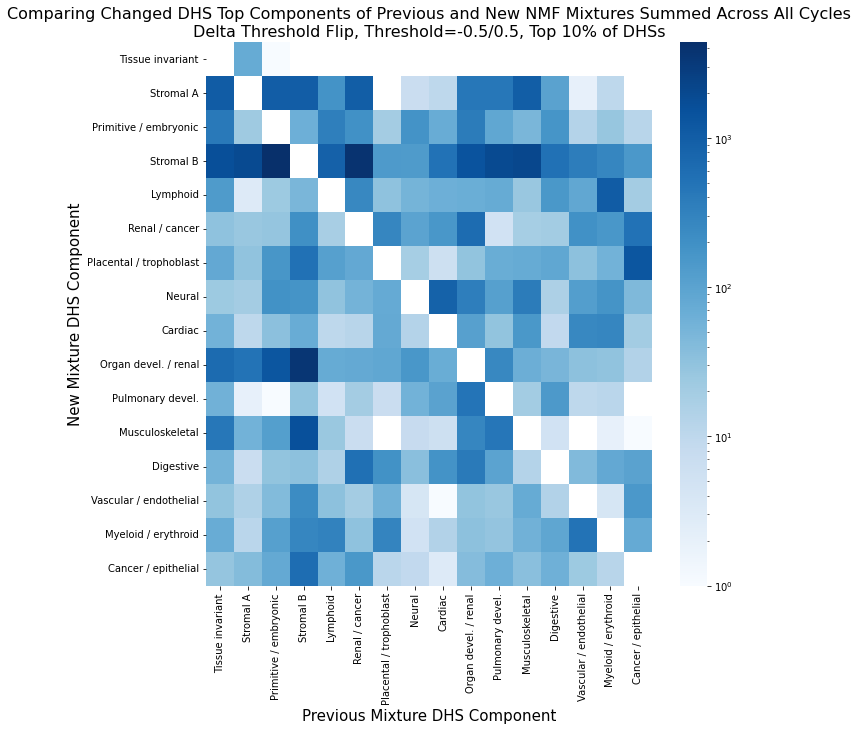

In [46]:
#in plots, yaxis is newest cycle, xaxis is previous cycle
comps_for_heatmap = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']

fig = plt.figure(figsize=(10,10))
fig.patch.set_facecolor('white')
ax = sns.heatmap(heatmap_mixture_all_cycles_10per_top_comp_comparison_sum, cmap='Blues', cbar=True, xticklabels=comps_for_heatmap, yticklabels=comps_for_heatmap, norm=LogNorm()) # 
ax.set_ylabel('New Mixture DHS Component', fontsize=15)
ax.set_xlabel('Previous Mixture DHS Component', fontsize=15)
ax.set_title('Comparing Changed DHS Top Components of Previous and New NMF Mixtures Summed Across All Cycles\nDelta Threshold Flip, Threshold=-0.5/0.5, Top 10% of DHSs', fontsize=16)

In [47]:
heatmap_basis_all_cycles_top_comp_comparison = np.zeros((3, 16,16), dtype=int)

changed_biosamples_all_cycles = []
changed_biosamples_original_comp = []
changed_biosamples_new_comp = []
changed_biosamples_original_comp_val = []
changed_biosamples_new_comp_val = []

for i in range(3):
    changed_biosamples_1_cycle = []
    original_comp = []
    new_comp = []
    original_comp_val = []
    new_comp_val = []
    
    for comp1, comp0, biosample, val1, val0 in zip(basis_all_cycles_top_comp_notall0[i+1], 
                                             basis_all_cycles_top_comp_notall0[i], 
                                             range(len(basis_all_cycles_top_comp_notall0[0])),
                                             basis_all_cycles_top_comp_val_notall0[i+1], 
                                             basis_all_cycles_top_comp_val_notall0[i],):
        if ((comp1!=comp0) and (~np.isnan(comp0)) and (~np.isnan(comp1))):
#             print(biosample)
            comp0 = comp0.astype(int)
            comp1 = comp1.astype(int)
#             print(comp0, comp1, val0, val1)
            heatmap_basis_all_cycles_top_comp_comparison[i, comp1, comp0] += 1
            changed_biosamples_1_cycle.append(biosample)
            original_comp.append(comp0)
            new_comp.append(comp1)
            original_comp_val.append(val0)
            new_comp_val.append(val1)
            
    changed_biosamples_all_cycles.append(np.array(changed_biosamples_1_cycle))
    changed_biosamples_original_comp.append(np.array(original_comp))
    changed_biosamples_new_comp.append(np.array(new_comp))
    changed_biosamples_original_comp_val.append(np.array(original_comp_val))
    changed_biosamples_new_comp_val.append(np.array(new_comp_val))

In [48]:
changed_biosamples_all_cycles_arr = []
for i in changed_biosamples_all_cycles:
    changed_biosamples_all_cycles_arr.extend(i)
changed_biosamples_all_cycles_arr = np.array(changed_biosamples_all_cycles_arr)
    
changed_biosamples_original_comp_arr = []
for i in changed_biosamples_original_comp:
    changed_biosamples_original_comp_arr.extend(i)
changed_biosamples_original_comp_arr = np.array(changed_biosamples_original_comp_arr)
    
changed_biosamples_new_comp_arr = []
for i in changed_biosamples_new_comp:
    changed_biosamples_new_comp_arr.extend(i)
changed_biosamples_new_comp_arr = np.array(changed_biosamples_new_comp_arr)
    
changed_biosamples_original_comp_val_arr = []
for i in changed_biosamples_original_comp_val:
    changed_biosamples_original_comp_val_arr.extend(i)
changed_biosamples_original_comp_val_arr = np.array(changed_biosamples_original_comp_val_arr)
    
changed_biosamples_new_comp_val_arr = []
for i in changed_biosamples_new_comp_val:
    changed_biosamples_new_comp_val_arr.extend(i)
changed_biosamples_new_comp_val_arr = np.array(changed_biosamples_new_comp_val_arr)

In [49]:
heatmap_basis_all_cycles_top_comp_comparison_sum = np.sum(heatmap_basis_all_cycles_top_comp_comparison, axis=0)

Text(0.5, 1.0, 'Comparing Changed DHS Top Components of Previous and New NMF Basis Summed Across All Cycles\nDelta Threshold Flip, Threshold=-0.5/0.5, Top 10% of DHSs')

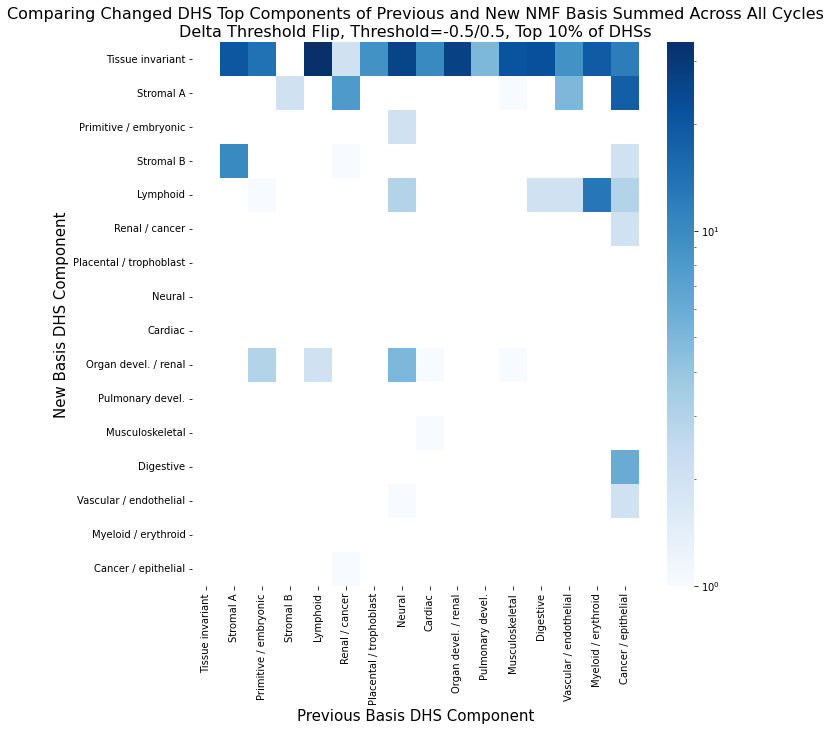

In [50]:
#in plots, yaxis is newest cycle, xaxis is previous cycle
comps_for_heatmap = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']

fig = plt.figure(figsize=(10,10))
fig.patch.set_facecolor('white')
ax = sns.heatmap(heatmap_basis_all_cycles_top_comp_comparison_sum, cmap='Blues', cbar=True, xticklabels=comps_for_heatmap, yticklabels=comps_for_heatmap, norm=LogNorm()) # 
ax.set_ylabel('New Basis DHS Component', fontsize=15)
ax.set_xlabel('Previous Basis DHS Component', fontsize=15)
ax.set_title('Comparing Changed DHS Top Components of Previous and New NMF Basis Summed Across All Cycles\nDelta Threshold Flip, Threshold=-0.5/0.5, Top 10% of DHSs', fontsize=16)

In [41]:
np.sum(heatmap_basis_all_cycles_top_comp_comparison[2])

35

**Top 15 Biosamples of each component**

In [51]:
top_15_biosample_inds = np.array(biosample_df[~biosample_df['Vocabulary representative'].isnull()].index)

In [53]:
changed_top15biosamples_all_cycles = []
changed_top15biosamples_original_comp_all_cycles = []
changed_top15biosamples_new_comp_all_cycles = []
for i in range(3):
    print(i)
    changed_top15biosamples_1_cycle = []
    changed_top15biosamples_original_comp_1_cycle = []
    changed_top15biosamples_new_comp_1_cycle = []
    for changed_biosample, old_comp, new_comp in zip(changed_biosamples_all_cycles[i], 
                                                     changed_biosamples_original_comp[i], 
                                                     changed_biosamples_new_comp[i]):
        
        if changed_biosample in top_15_biosample_inds:
            print(changed_biosample, biosample_df.loc[changed_biosample]['Biosample name'], comps_for_heatmap[old_comp], comps_for_heatmap[new_comp])
            changed_top15biosamples_1_cycle.append(changed_biosample)
            changed_top15biosamples_original_comp_1_cycle.append(old_comp)
            changed_top15biosamples_new_comp_1_cycle.append(new_comp)
            
    changed_top15biosamples_all_cycles.append(np.array(changed_top15biosamples_1_cycle))
    changed_top15biosamples_original_comp_all_cycles.append(np.array(changed_top15biosamples_original_comp_1_cycle))
    changed_top15biosamples_new_comp_all_cycles.append(np.array(changed_top15biosamples_new_comp_1_cycle))

0
94 HEEpiC Cancer / epithelial Stromal A
681 Trophoblast Placental / trophoblast Tissue invariant
732 fPlacenta Placental / trophoblast Tissue invariant
1
114 HMVEC_LLy Vascular / endothelial Tissue invariant
303 fPlacenta Placental / trophoblast Tissue invariant
342 MCF7 Cancer / epithelial Digestive
343 MCF7_ER Cancer / epithelial Digestive
357 MCF7_ER Cancer / epithelial Digestive
423 fPlacenta Placental / trophoblast Tissue invariant
425 fHeart Cardiac Organ devel. / renal
545 fRetina Neural Tissue invariant
628 PC9 Cancer / epithelial Stromal A
645 renal_cell_carcinoma Renal / cancer Stromal A
677 renal_cell_carcinoma Renal / cancer Stromal A
682 fPlacenta Placental / trophoblast Tissue invariant
2
107 HMVEC_dNeo Vascular / endothelial Tissue invariant
108 HMVEC_dNeo Vascular / endothelial Tissue invariant
121 HMVEC_dLyAd Vascular / endothelial Tissue invariant
122 HMVEC_dLyAd Vascular / endothelial Tissue invariant
290 fKidney_renal_cortex Organ devel. / renal Tissue invariant
3

In [234]:
biosample_df.loc[changed_top15biosamples_all_cycles[0]]

,library order,Biosample name,Vocabulary representative,DCC Experiment ID,DCC Library ID,DCC Biosample ID,Altius Aggregation ID,Altius Library ID,Altius Biosample ID,Replicate indicators,...,Library cleanup,DNaseI units/mL,Amount Nucleic Acid (ng),Nuclei count,Protease inhibitor,Library sequencing date,Reads used,DCC SPOT score,Per-biosample peaks,DHSs in Index
94,95,HEEpiC,Cancer / epithelial,ENCSR000ENN,ENCLB477ZZZ,ENCBS515HSH,AG4144,LN2614,DS12768,DS12763,...,minElute,160.0,21.1,NaN,NaN,2009-10-23,25615600,0.5532,91114,91036
681,682,Trophoblast,Placental / trophoblast,ENCSR121ZSL,ENCLB686KFW,ENCBS478CDB,AG3848,LN31423S,DS35778S,DS30587A,...,NaN,NaN,NaN,510000.0,Buffer A,2015-03-14,176599134,0.5038,84161,83697
732,733,fPlacenta,Placental / trophoblast,ENCSR552XJI,ENCLB711ZZZ,ENCBS723HLT,AG7450,LN45076C,DS37716C,NaN,...,NaN,NaN,0.972,1380000.0,A+Sucrose,NaN,206456483,0.4356,115898,114344


In [235]:
biosample_df.loc[changed_top15biosamples_all_cycles[1]]

,library order,Biosample name,Vocabulary representative,DCC Experiment ID,DCC Library ID,DCC Biosample ID,Altius Aggregation ID,Altius Library ID,Altius Biosample ID,Replicate indicators,...,Library cleanup,DNaseI units/mL,Amount Nucleic Acid (ng),Nuclei count,Protease inhibitor,Library sequencing date,Reads used,DCC SPOT score,Per-biosample peaks,DHSs in Index
114,115,HMVEC_LLy,Vascular / endothelial,ENCSR000EOE,ENCLB511ZZZ,ENCBS776PUN,AG4128,LN2734,DS13193,DS13185,...,minElute,160.0,16.4,NaN,NaN,2009-12-16,29726039,0.5489,76414,76303
303,304,fPlacenta,Placental / trophoblast,ENCSR129TSG,ENCLB452OOX,ENCBS688ZPB,AG9027,LN4046,DS17639,NaN,...,minElute,60.0,26.4,6780000.0,A+Sucrose,2011-01-03,72846511,0.3566,106238,106026
342,343,MCF7,Cancer / epithelial,ENCSR000EPH,ENCLB549ZZZ,ENCBS267CRP,AG4052,LN4130,DS18021,DS18267,...,minElute,120.0,66.9,10000000.0,NaN,2011-02-09,77273673,0.5545,155466,155238
343,344,MCF7_ER,Cancer / epithelial,ENCSR000EPI,ENCLB551ZZZ,ENCBS134PJO,AG4051,LN4131,DS18025,DS18271,...,minElute,120.0,83.1,10000000.0,NaN,2011-02-09,73180365,0.5137,137690,137441
357,358,MCF7_ER,Cancer / epithelial,ENCSR000EPI,ENCLB552ZZZ,ENCBS037ENC,AG4046,LN4170,DS18271,DS18025,...,minElute,100.0,34.3,10000000.0,NaN,2011-03-02,44849860,0.6608,122349,122184
423,424,fPlacenta,Placental / trophoblast,ENCSR648RAX,ENCLB558ALO,ENCBS755ISG,AG8906,LN4525,DS19391,NaN,...,minElute,60.0,16.7,4560000.0,A+Sucrose,2011-06-13,34069627,0.5477,84669,84506
425,426,fHeart,Cardiac,ENCSR064GBK,ENCLB629CQG,ENCBS407ALA,AG8904,LN4529,DS19431,NaN,...,minElute,80.0,7.8,4590000.0,A+Sucrose,2011-06-15,37454064,0.6242,74897,74683
545,546,fRetina,Neural,ENCSR474GZQ,ENCLB238FWZ,ENCBS797BYT,AG3881,LN20434,DS23286,NaN,...,Sucrose,80.0,NaN,8100000.0,A+Sucrose,2013-01-22,214856308,0.4530,142045,139232
628,629,PC9,Cancer / epithelial,ENCSR940NLN,ENCLB625GCM,ENCBS480XRH,AG3917,LN26744A,DS27166A,DS27163A,...,NaN,NaN,10,2670000.0,PBS+A,2014-04-08,308725639,0.5168,173735,173039
645,646,renal_cell_carcinoma,Renal / cancer,ENCSR337IRF,ENCLB249NSX,ENCBS482LEL,AG6993,LN26972B,DS26692B,DS26693A,...,Sucrose,80.0,31,NaN,NaN,2014-02-27,52988782,0.6081,89787,89732


In [236]:
biosample_df.loc[changed_top15biosamples_all_cycles[2]]

,library order,Biosample name,Vocabulary representative,DCC Experiment ID,DCC Library ID,DCC Biosample ID,Altius Aggregation ID,Altius Library ID,Altius Biosample ID,Replicate indicators,...,Library cleanup,DNaseI units/mL,Amount Nucleic Acid (ng),Nuclei count,Protease inhibitor,Library sequencing date,Reads used,DCC SPOT score,Per-biosample peaks,DHSs in Index
107,108,HMVEC_dNeo,Vascular / endothelial,ENCSR000EOC,ENCLB506ZZZ,ENCBS692KAB,AG4136,LN2660,DS12929,DS12937,...,minElute,160.0,16,NaN,NaN,2009-11-12,36953153,0.4408,74545,74419
108,109,HMVEC_dNeo,Vascular / endothelial,ENCSR000EOC,ENCLB507ZZZ,ENCBS317AAA,AG4135,LN2662,DS12937,DS12929,...,minElute,160.0,20.2,NaN,NaN,2009-11-12,29141689,0.5858,77215,77096
121,122,HMVEC_dLyAd,Vascular / endothelial,ENCSR000EOA,ENCLB502ZZZ,ENCBS633QEK,AG4125,LN2749,DS13256,DS13261,...,minElute,160.0,12.9,NaN,NaN,2009-12-21,34367492,0.5887,83520,83400
122,123,HMVEC_dLyAd,Vascular / endothelial,ENCSR000EOA,ENCLB503ZZZ,ENCBS315AAA,AG4124,LN2750,DS13261,DS13256,...,minElute,160.0,8.3,NaN,NaN,2009-12-21,32669497,0.5582,78076,77980
290,291,fKidney_renal_cortex,Organ devel. / renal,ENCSR155NPL,ENCLB175FUL,ENCBS766EWQ,AG9038,LN3969,DS17455,NaN,...,minElute,60.0,11.9,5220000.0,A+Sucrose,2010-12-03,29222868,0.6276,69687,69496
357,358,MCF7_ER,Cancer / epithelial,ENCSR000EPI,ENCLB552ZZZ,ENCBS037ENC,AG4046,LN4170,DS18271,DS18025,...,minElute,100.0,34.3,10000000.0,NaN,2011-03-02,44849860,0.6608,122349,122184
425,426,fHeart,Cardiac,ENCSR064GBK,ENCLB629CQG,ENCBS407ALA,AG8904,LN4529,DS19431,NaN,...,minElute,80.0,7.8,4590000.0,A+Sucrose,2011-06-15,37454064,0.6242,74897,74683
477,478,fKidney_renal_pelvis,Organ devel. / renal,ENCSR911YVV,ENCLB859DRY,ENCBS404JFE,AG8860,LN4873,DS20570,NaN,...,minElute,60.0,22.6,4590000.0,A+Sucrose,2011-10-05,40423796,0.5152,71283,70986
509,510,fPlacenta,Placental / trophoblast,ENCSR545KQR,ENCLB460PPD,ENCBS171TKY,AG8832,LN10068,DS20793,NaN,...,NaN,60.0,NaN,7770000.0,A+Sucrose,2011-10-26,44039880,0.5832,109857,109707
518,519,fKidney_renal_cortex,Organ devel. / renal,ENCSR656QYL,ENCLB328FBF,ENCBS345NEG,AG8823,LN10079,DS20445,NaN,...,NaN,60.0,NaN,10940000.0,A+Sucrose,2011-09-22,48061574,0.3791,73570,73317
